# EuroSAT Multispectral (MS) — Exploratory Data Analysis

**Project:** Land-Type Classification using Sentinel-2  
**Notebook goal:** inspect the dataset, validate the multispectral format, explore class balance and image shapes, visualize samples and spectral bands, summarize per-class spectral signatures, and export figures/tables.

> **Important:** This notebook is for **EuroSAT MS**, not the 3-channel RGB version. It does not invent results or modify the raw dataset. Results are calculated from the files found on your computer.

## 0. Setup and requirements

Run this cell first. If a package is missing, install the packages listed in `requirements.txt` or run the optional install command below.

For GeoTIFF reading, this notebook uses `rasterio`. No PyTorch or `torchvision` is required for this EDA notebook.

In [1]:
# If needed, uncomment and run once:
# %pip install numpy pandas matplotlib seaborn rasterio pillow

import os
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

print("Python EDA environment ready.")

Python EDA environment ready.


## 1. Find the project root and dataset

Expected default location:

```text
satellite_empty/
├── data/
│   └── raw/
│       └── EuroSAT_MS/
│           ├── AnnualCrop/
│           ├── Forest/
│           └── ...
└── notebooks/
    └── 01_data_exploration_eurosat_ms.ipynb
```

The code below checks likely project locations and searches `data/raw` for class folders and supported files. If your dataset folder has a different name, set `DATA_DIR` manually in the configuration cell.

In [2]:
def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    candidates = [start, *start.parents]
    for candidate in candidates:
        if (candidate / "data").exists() and (candidate / "notebooks").exists():
            return candidate
    # Common case: notebook kernel starts in the notebooks folder
    if start.name.lower() == "notebooks":
        return start.parent
    return start

PROJECT_ROOT = find_project_root()
DATA_RAW = PROJECT_ROOT / "data" / "raw"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
TABLES_DIR = PROJECT_ROOT / "reports" / "tables"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

# Set this explicitly if your MS dataset lives somewhere else:
# DATA_DIR = Path(r"C:/path/to/EuroSAT_MS")
DATA_DIR = None

print("Current working directory:", Path.cwd().resolve())
print("Project root:", PROJECT_ROOT)
print("Raw data folder:", DATA_RAW)
print("Figures output:", FIGURES_DIR)
print("Tables output:", TABLES_DIR)

Current working directory: C:\Users\HP\Downloads\satellite_empty\notebooks
Project root: C:\Users\HP\Downloads\satellite_empty
Raw data folder: C:\Users\HP\Downloads\satellite_empty\data\raw
Figures output: C:\Users\HP\Downloads\satellite_empty\reports\figures
Tables output: C:\Users\HP\Downloads\satellite_empty\reports\tables


In [3]:
from pathlib import Path

SUPPORTED_EXTENSIONS = {".tif", ".tiff", ".npy", ".npz"}

DATA_DIR = Path(
    r"C:\Users\HP\Downloads\satellite_empty\EuroSAT_MS\EuroSAT_MS"
).resolve()

print("Dataset search path:", DATA_DIR)
print("Path exists:", DATA_DIR.exists())

if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Dataset path not found: {DATA_DIR}\n"
        "Please check the actual EuroSAT MS dataset location."
    )

top_level = sorted(
    DATA_DIR.iterdir(),
    key=lambda p: p.name.lower()
)

print("\nTop-level contents (first 30):")

for p in top_level[:30]:
    print("DIR " if p.is_dir() else "FILE", p.name)

Dataset search path: C:\Users\HP\Downloads\satellite_empty\EuroSAT_MS\EuroSAT_MS
Path exists: True

Top-level contents (first 30):
DIR  AnnualCrop
DIR  Forest
DIR  HerbaceousVegetation
DIR  Highway
DIR  Industrial
DIR  Pasture
DIR  PermanentCrop
DIR  Residential
DIR  River
DIR  SeaLake


## 2. Build a file inventory

This step detects class folders and creates a table of candidate image files. It supports GeoTIFF (`.tif`, `.tiff`) and NumPy arrays (`.npy`, `.npz`).

If files are organized in class subfolders, the folder name is used as the class label. If files are flat, the notebook uses the parent folder name and clearly reports that the structure may need manual review.

In [4]:
all_files = [
    p for p in DATA_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in SUPPORTED_EXTENSIONS
]

if not all_files:
    raise RuntimeError(
        f"No supported MS files ({', '.join(sorted(SUPPORTED_EXTENSIONS))}) were found under {DATA_DIR}. "
        "Check that the multispectral dataset is extracted here. RGB .jpg/.png files are not the MS dataset."
    )

records = []
for path in sorted(all_files):
    # Use the closest directory under DATA_DIR as the class when possible.
    relative_parent = path.parent.relative_to(DATA_DIR)
    if len(relative_parent.parts) >= 1:
        label = relative_parent.parts[0]
    else:
        label = path.parent.name
    records.append({
        "path": str(path),
        "relative_path": str(path.relative_to(DATA_DIR)),
        "class": label,
        "extension": path.suffix.lower(),
        "size_kb": round(path.stat().st_size / 1024, 2),
    })

df = pd.DataFrame(records)
print("Total candidate files:", len(df))
print("Number of detected labels:", df["class"].nunique())
display(df.head())

Total candidate files: 27000
Number of detected labels: 10


,path,relative_path,class,extension,size_kb
0,C:\Users\HP\Downloads\satellite_empty\EuroSAT_...,AnnualCrop\AnnualCrop_1.tif,AnnualCrop,.tif,104.73
1,C:\Users\HP\Downloads\satellite_empty\EuroSAT_...,AnnualCrop\AnnualCrop_10.tif,AnnualCrop,.tif,104.73
2,C:\Users\HP\Downloads\satellite_empty\EuroSAT_...,AnnualCrop\AnnualCrop_100.tif,AnnualCrop,.tif,104.73
3,C:\Users\HP\Downloads\satellite_empty\EuroSAT_...,AnnualCrop\AnnualCrop_1000.tif,AnnualCrop,.tif,104.73
4,C:\Users\HP\Downloads\satellite_empty\EuroSAT_...,AnnualCrop\AnnualCrop_1001.tif,AnnualCrop,.tif,104.73


## 3. Validate dataset structure and class distribution

EuroSAT commonly contains 10 land-cover classes. The notebook does not assume every dataset copy has the same number of files; it reports what is actually present.

,class,image_count
0,AnnualCrop,3000
1,Forest,3000
2,HerbaceousVegetation,3000
3,Residential,3000
4,SeaLake,3000
5,Highway,2500
6,PermanentCrop,2500
7,Industrial,2500
8,River,2500
9,Pasture,2000


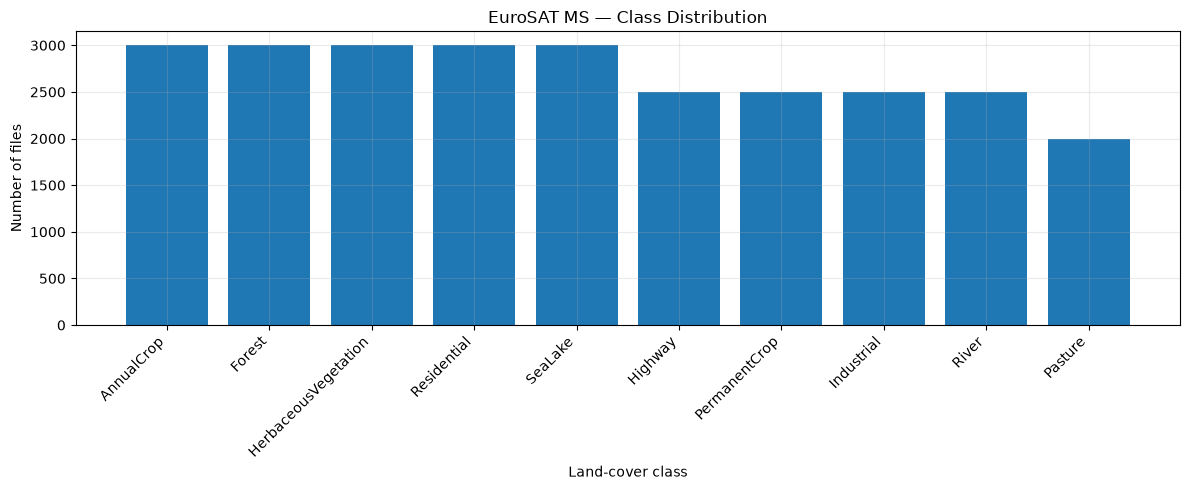

Class count: 10
Smallest class: Pasture = 2000
Largest class: AnnualCrop = 3000


In [5]:
class_counts = (
    df.groupby("class")
      .size()
      .sort_values(ascending=False)
      .rename("image_count")
      .reset_index()
)

display(class_counts)
class_counts.to_csv(TABLES_DIR / "class_distribution.csv", index=False)

plt.figure(figsize=(12, 5))
plt.bar(class_counts["class"], class_counts["image_count"])
plt.xticks(rotation=45, ha="right")
plt.xlabel("Land-cover class")
plt.ylabel("Number of files")
plt.title("EuroSAT MS — Class Distribution")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "class_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

print("Class count:", df["class"].nunique())
print("Smallest class:", class_counts.iloc[-1]["class"], "=", class_counts.iloc[-1]["image_count"])
print("Largest class:", class_counts.iloc[0]["class"], "=", class_counts.iloc[0]["image_count"])

## 4. Load multispectral files safely

The loader returns arrays in **(bands, height, width)** order when possible. For GeoTIFF, `rasterio` naturally reads this layout. NumPy arrays are inspected and converted only when the band axis can be inferred reasonably.

If a file cannot be read, the error is reported rather than silently fabricating a value.

In [6]:
def load_multispectral(path):
    path = Path(path)
    suffix = path.suffix.lower()

    if suffix in {".tif", ".tiff"}:
        try:
            import rasterio
        except ImportError as exc:
            raise ImportError(
                "The package rasterio is required for GeoTIFF files. Run: %pip install rasterio"
            ) from exc
        with rasterio.open(path) as src:
            arr = src.read()
            metadata = {
                "driver": src.driver,
                "count": src.count,
                "width": src.width,
                "height": src.height,
                "dtype": str(src.dtypes[0]) if src.count else None,
                "crs": str(src.crs) if src.crs else None,
            }
        return np.asarray(arr), metadata

    if suffix == ".npy":
        arr = np.load(path, allow_pickle=False)
        return normalize_numpy_layout(arr), {"driver": "NumPy .npy"}

    if suffix == ".npz":
        archive = np.load(path, allow_pickle=False)
        keys = list(archive.files)
        if not keys:
            raise ValueError(f"No arrays found in archive: {path}")
        arr = archive[keys[0]]
        return normalize_numpy_layout(arr), {"driver": "NumPy .npz", "array_key": keys[0], "keys": keys}

    raise ValueError(f"Unsupported file extension: {suffix}")


def normalize_numpy_layout(arr):
    arr = np.asarray(arr)
    if arr.ndim == 2:
        return arr[np.newaxis, :, :]
    if arr.ndim != 3:
        raise ValueError(f"Expected a 2D or 3D array, got shape {arr.shape}")
    # If first axis is a plausible band count, assume (bands, height, width).
    if arr.shape[0] <= 20 and arr.shape[1] > 20 and arr.shape[2] > 20:
        return arr
    # If last axis is a plausible band count, convert (height, width, bands) to CHW.
    if arr.shape[-1] <= 20 and arr.shape[0] > 20 and arr.shape[1] > 20:
        return np.moveaxis(arr, -1, 0)
    # Leave ambiguous shapes unchanged but surface them in the report.
    return arr


# Find the first readable sample, reporting failures as we go.
sample_path = None
sample_array = None
sample_metadata = None
read_errors = []

for candidate in df["path"]:
    try:
        arr, meta = load_multispectral(candidate)
        if arr.ndim == 3:
            sample_path, sample_array, sample_metadata = candidate, arr, meta
            break
        read_errors.append((candidate, f"Unexpected dimensions: {arr.shape}"))
    except Exception as exc:
        read_errors.append((candidate, repr(exc)))

if sample_array is None:
    raise RuntimeError(
        "Could not read any 3D multispectral sample. Review file formats and errors. "
        f"First errors: {read_errors[:3]}"
    )

print("Sample file:", sample_path)
print("Sample array shape (bands, height, width):", sample_array.shape)
print("Sample dtype:", sample_array.dtype)
print("Sample min/max:", np.nanmin(sample_array), "/", np.nanmax(sample_array))
print("Reader metadata:", sample_metadata)
if read_errors:
    print(f"Note: {len(read_errors)} files failed before the first readable sample.")

Sample file: C:\Users\HP\Downloads\satellite_empty\EuroSAT_MS\EuroSAT_MS\AnnualCrop\AnnualCrop_1.tif
Sample array shape (bands, height, width): (13, 64, 64)
Sample dtype: uint16
Sample min/max: 9 / 3490
Reader metadata: {'driver': 'GTiff', 'count': 13, 'width': 64, 'height': 64, 'dtype': 'uint16', 'crs': 'EPSG:32635'}


## 5. Image shape, dtype, and band-count audit

This section samples files from the inventory to check whether dimensions, data types, and band counts are consistent. The audit is limited to a configurable number of files to keep execution practical on a laptop.

In [7]:
MAX_AUDIT_FILES = min(300, len(df))
audit_records = []
audit_errors = []

for _, row in df.head(MAX_AUDIT_FILES).iterrows():
    try:
        arr, meta = load_multispectral(row["path"])
        audit_records.append({
            "path": row["relative_path"],
            "class": row["class"],
            "shape": tuple(arr.shape),
            "bands": arr.shape[0] if arr.ndim == 3 else np.nan,
            "height": arr.shape[1] if arr.ndim == 3 else np.nan,
            "width": arr.shape[2] if arr.ndim == 3 else np.nan,
            "dtype": str(arr.dtype),
            "min": float(np.nanmin(arr)),
            "max": float(np.nanmax(arr)),
        })
    except Exception as exc:
        audit_errors.append({"path": row["relative_path"], "error": repr(exc)})

audit_df = pd.DataFrame(audit_records)
print(f"Files inspected: {len(audit_df)} / {MAX_AUDIT_FILES}")
print("Read errors:", len(audit_errors))
if not audit_df.empty:
    print("\nBand counts:")
    display(audit_df["bands"].value_counts(dropna=False).sort_index().rename_axis("bands").to_frame("files"))
    print("\nImage shapes (top 10):")
    display(audit_df["shape"].value_counts().head(10).rename_axis("shape").to_frame("files"))
    print("\nDtypes:")
    display(audit_df["dtype"].value_counts().rename_axis("dtype").to_frame("files"))
    audit_df.to_csv(TABLES_DIR / "image_audit_sample.csv", index=False)

if audit_errors:
    display(pd.DataFrame(audit_errors).head(10))

Files inspected: 300 / 300
Read errors: 0

Band counts:


,files
bands,
13,300



Image shapes (top 10):


,files
shape,
"(13, 64, 64)",300



Dtypes:


,files
dtype,
uint16,300


## 6. Visualize a multispectral image as an RGB composite

A multispectral image has more than three bands, so an RGB composite is created by selecting three bands for display. The default uses Sentinel-2 bands B04 (red), B03 (green), and B02 (blue), corresponding to indices 3, 2, and 1 in the standard 13-band ordering.

This is only a visualization composite; it does not convert the source data to RGB. If the file contains fewer than four bands, the notebook falls back to the first three bands.

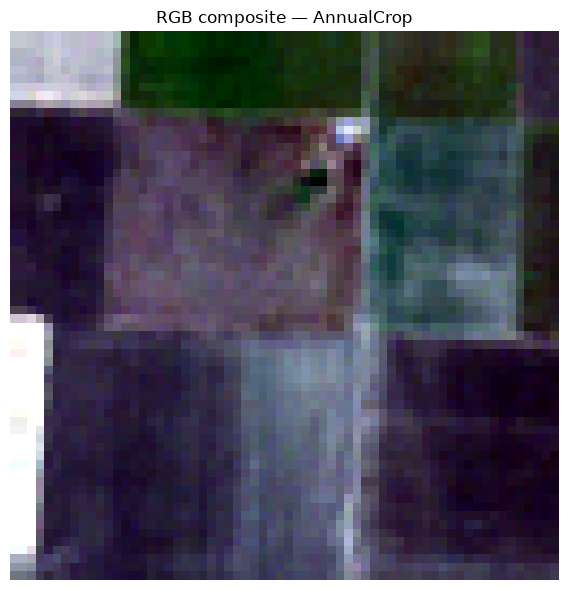

In [8]:
STANDARD_BAND_NAMES = [
    "B01", "B02", "B03", "B04", "B05", "B06", "B07",
    "B08", "B8A", "B09", "B10", "B11", "B12"
]
STANDARD_WAVELENGTHS_NM = [443, 490, 560, 665, 705, 740, 783, 842, 865, 945, 1375, 1610, 2190]


def stretch_band(band, low=2, high=98):
    band = np.asarray(band, dtype=np.float32)
    valid = np.isfinite(band)
    if not valid.any():
        return np.zeros_like(band, dtype=np.float32)
    lo, hi = np.nanpercentile(band[valid], [low, high])
    if hi <= lo:
        return np.zeros_like(band, dtype=np.float32)
    scaled = (band - lo) / (hi - lo)
    return np.clip(scaled, 0, 1)


def make_rgb_composite(arr):
    if arr.shape[0] >= 4:
        # Standard Sentinel-2 order: B04=red index 3, B03=green index 2, B02=blue index 1.
        rgb = np.stack([arr[3], arr[2], arr[1]], axis=-1)
    elif arr.shape[0] >= 3:
        rgb = np.stack([arr[0], arr[1], arr[2]], axis=-1)
    else:
        one = stretch_band(arr[0])
        return np.stack([one, one, one], axis=-1)
    return np.stack([stretch_band(rgb[..., i]) for i in range(3)], axis=-1)


rgb_sample = make_rgb_composite(sample_array)
plt.figure(figsize=(6, 6))
plt.imshow(rgb_sample)
plt.title(f"RGB composite — {Path(sample_path).parent.name}")
plt.axis("off")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "sample_rgb_composite.png", dpi=200, bbox_inches="tight")
plt.show()

## 7. Show sample composites from each class

The notebook attempts to load one readable sample from each detected class and displays an RGB composite. Classes without readable files are skipped and reported.

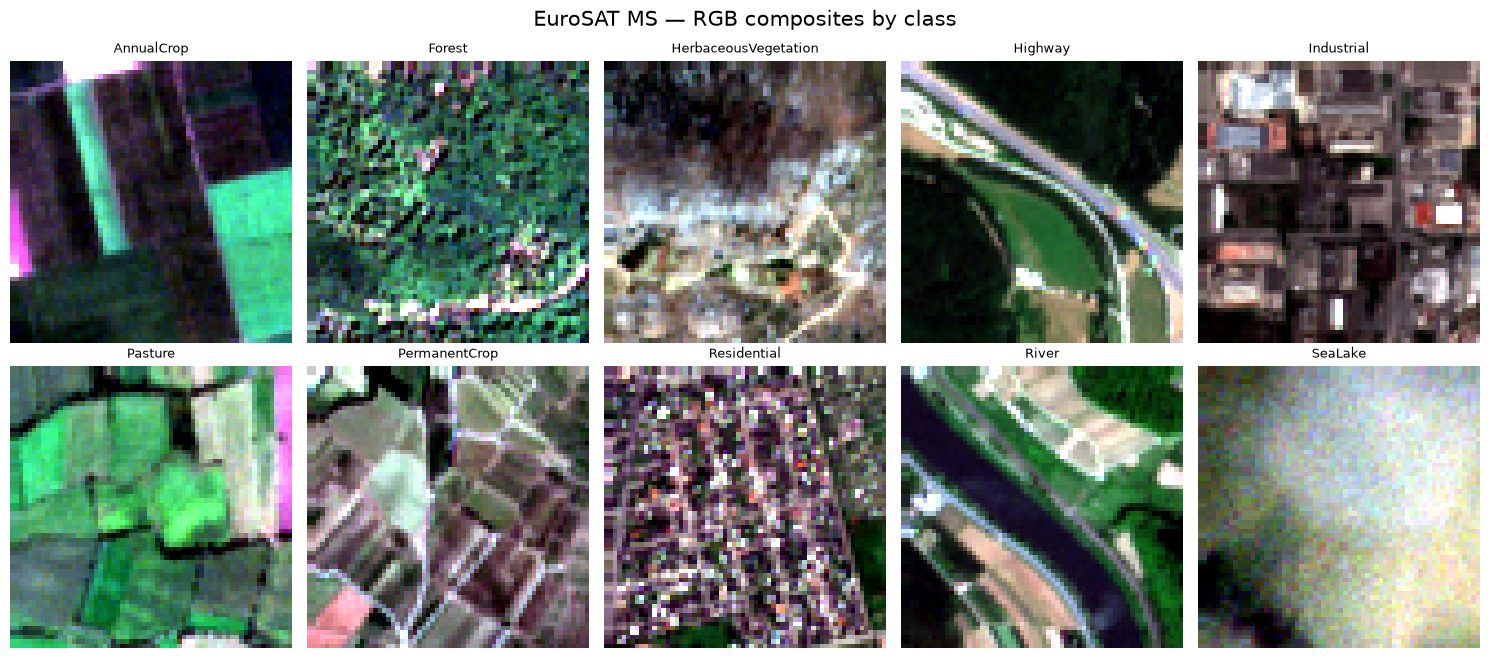

In [9]:
MAX_CLASSES_TO_DISPLAY = 10
classes_to_show = sorted(df["class"].unique())[:MAX_CLASSES_TO_DISPLAY]
sample_images = []
sample_labels = []
sample_failures = []

for label in classes_to_show:
    candidates = df.loc[df["class"] == label, "path"].tolist()
    random.shuffle(candidates)
    loaded = False
    for candidate in candidates[:20]:
        try:
            arr, _ = load_multispectral(candidate)
            if arr.ndim == 3:
                sample_images.append(make_rgb_composite(arr))
                sample_labels.append(label)
                loaded = True
                break
        except Exception as exc:
            sample_failures.append((candidate, repr(exc)))
    if not loaded:
        sample_failures.append((label, "No readable sample found among first 20 candidates"))

if sample_images:
    n = len(sample_images)
    cols = 5
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(15, 3.4 * rows))
    axes = np.array(axes).reshape(-1)
    for ax in axes:
        ax.axis("off")
    for ax, image, label in zip(axes, sample_images, sample_labels):
        ax.imshow(image)
        ax.set_title(label, fontsize=9)
        ax.axis("off")
    fig.suptitle("EuroSAT MS — RGB composites by class", fontsize=15)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "sample_images_by_class.png", dpi=200, bbox_inches="tight")
    plt.show()
else:
    print("No sample images could be visualized.")

if sample_failures:
    print("Skipped/failed sample attempts:", len(sample_failures))

## 8. Visualize individual bands

This figure displays up to the first 13 bands from the sample. Band labels use the standard Sentinel-2 naming only when the array has the expected 13-band layout. Verify the dataset documentation if your files use a different order.

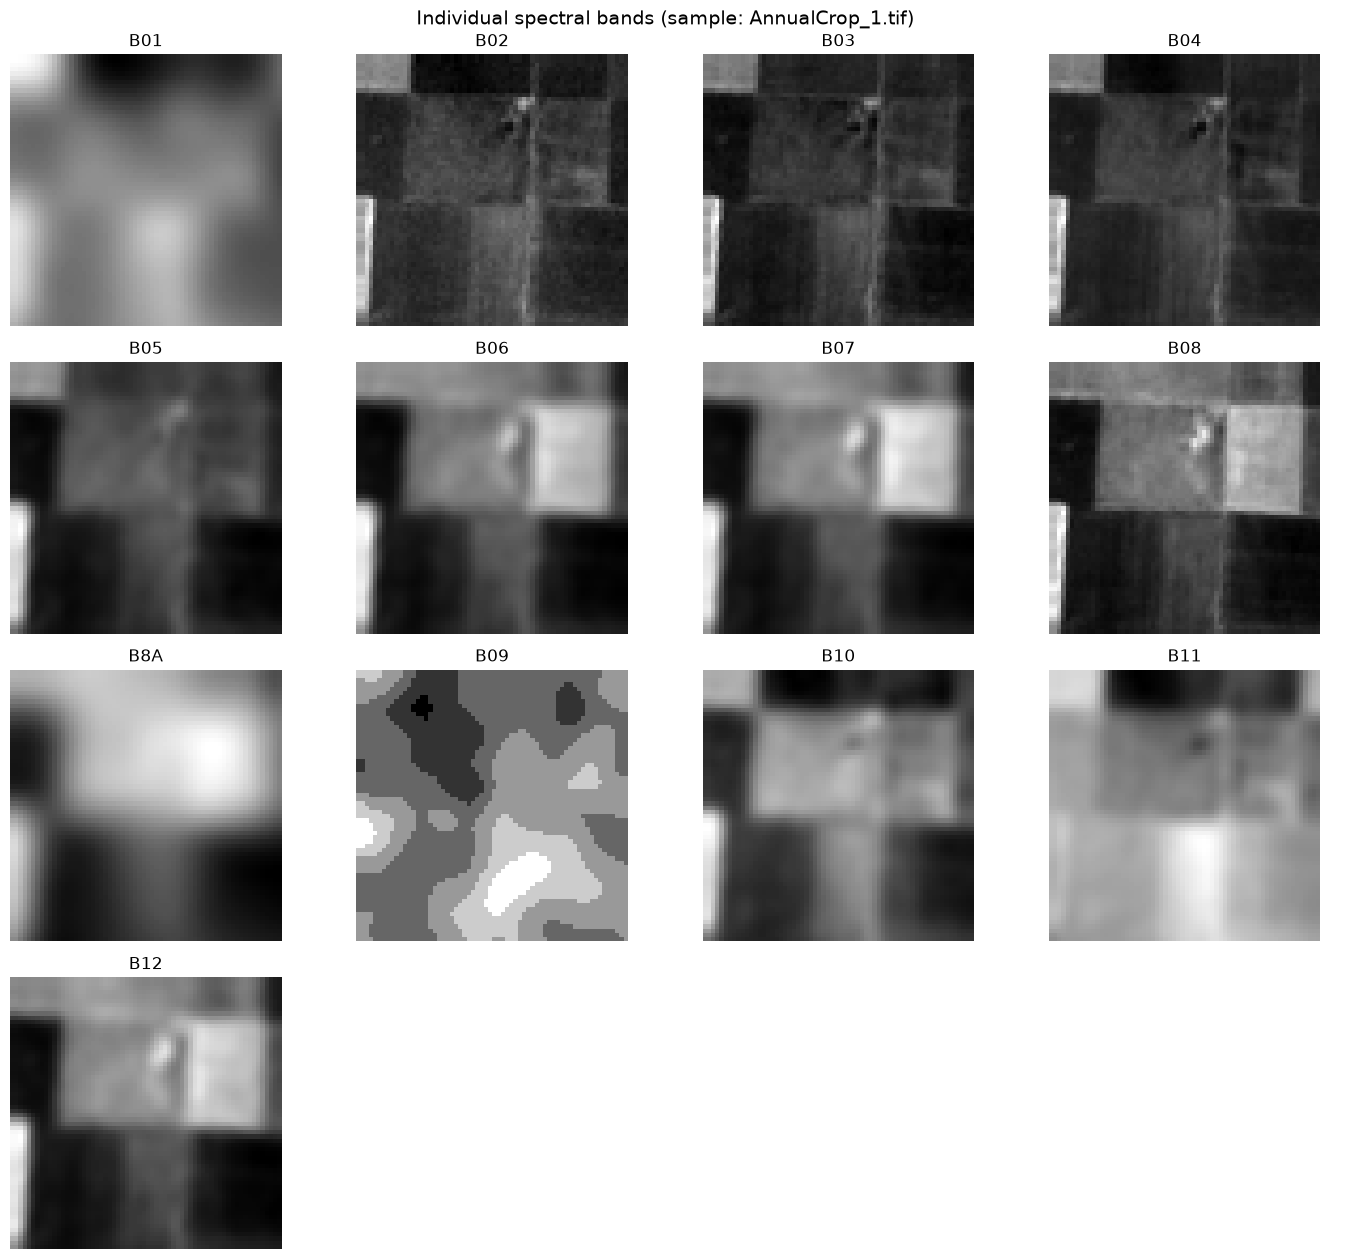

Detected bands in sample: 13
The sample has 13 bands, consistent with the standard EuroSAT MS layout.


In [10]:
n_bands = sample_array.shape[0]
n_show = min(n_bands, 13)
cols = 4
rows = int(np.ceil(n_show / cols))
fig, axes = plt.subplots(rows, cols, figsize=(14, 3.2 * rows))
axes = np.array(axes).reshape(-1)

for i, ax in enumerate(axes):
    ax.axis("off")
    if i < n_show:
        ax.imshow(sample_array[i], cmap="gray")
        band_label = STANDARD_BAND_NAMES[i] if n_bands == 13 else f"Band {i + 1}"
        ax.set_title(band_label)

fig.suptitle(f"Individual spectral bands (sample: {Path(sample_path).name})", fontsize=14)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "individual_bands.png", dpi=200, bbox_inches="tight")
plt.show()

print("Detected bands in sample:", n_bands)
if n_bands == 13:
    print("The sample has 13 bands, consistent with the standard EuroSAT MS layout.")
elif n_bands == 3:
    print("WARNING: This sample has only 3 bands and may be RGB data, not multispectral.")
else:
    print("Check the dataset source and array layout before interpreting band-specific results.")

## 9. Pixel-value distributions by band

For efficiency, histograms are calculated from a random subset of pixels in the sample image. This helps compare the value ranges and distributions across bands without plotting every pixel.

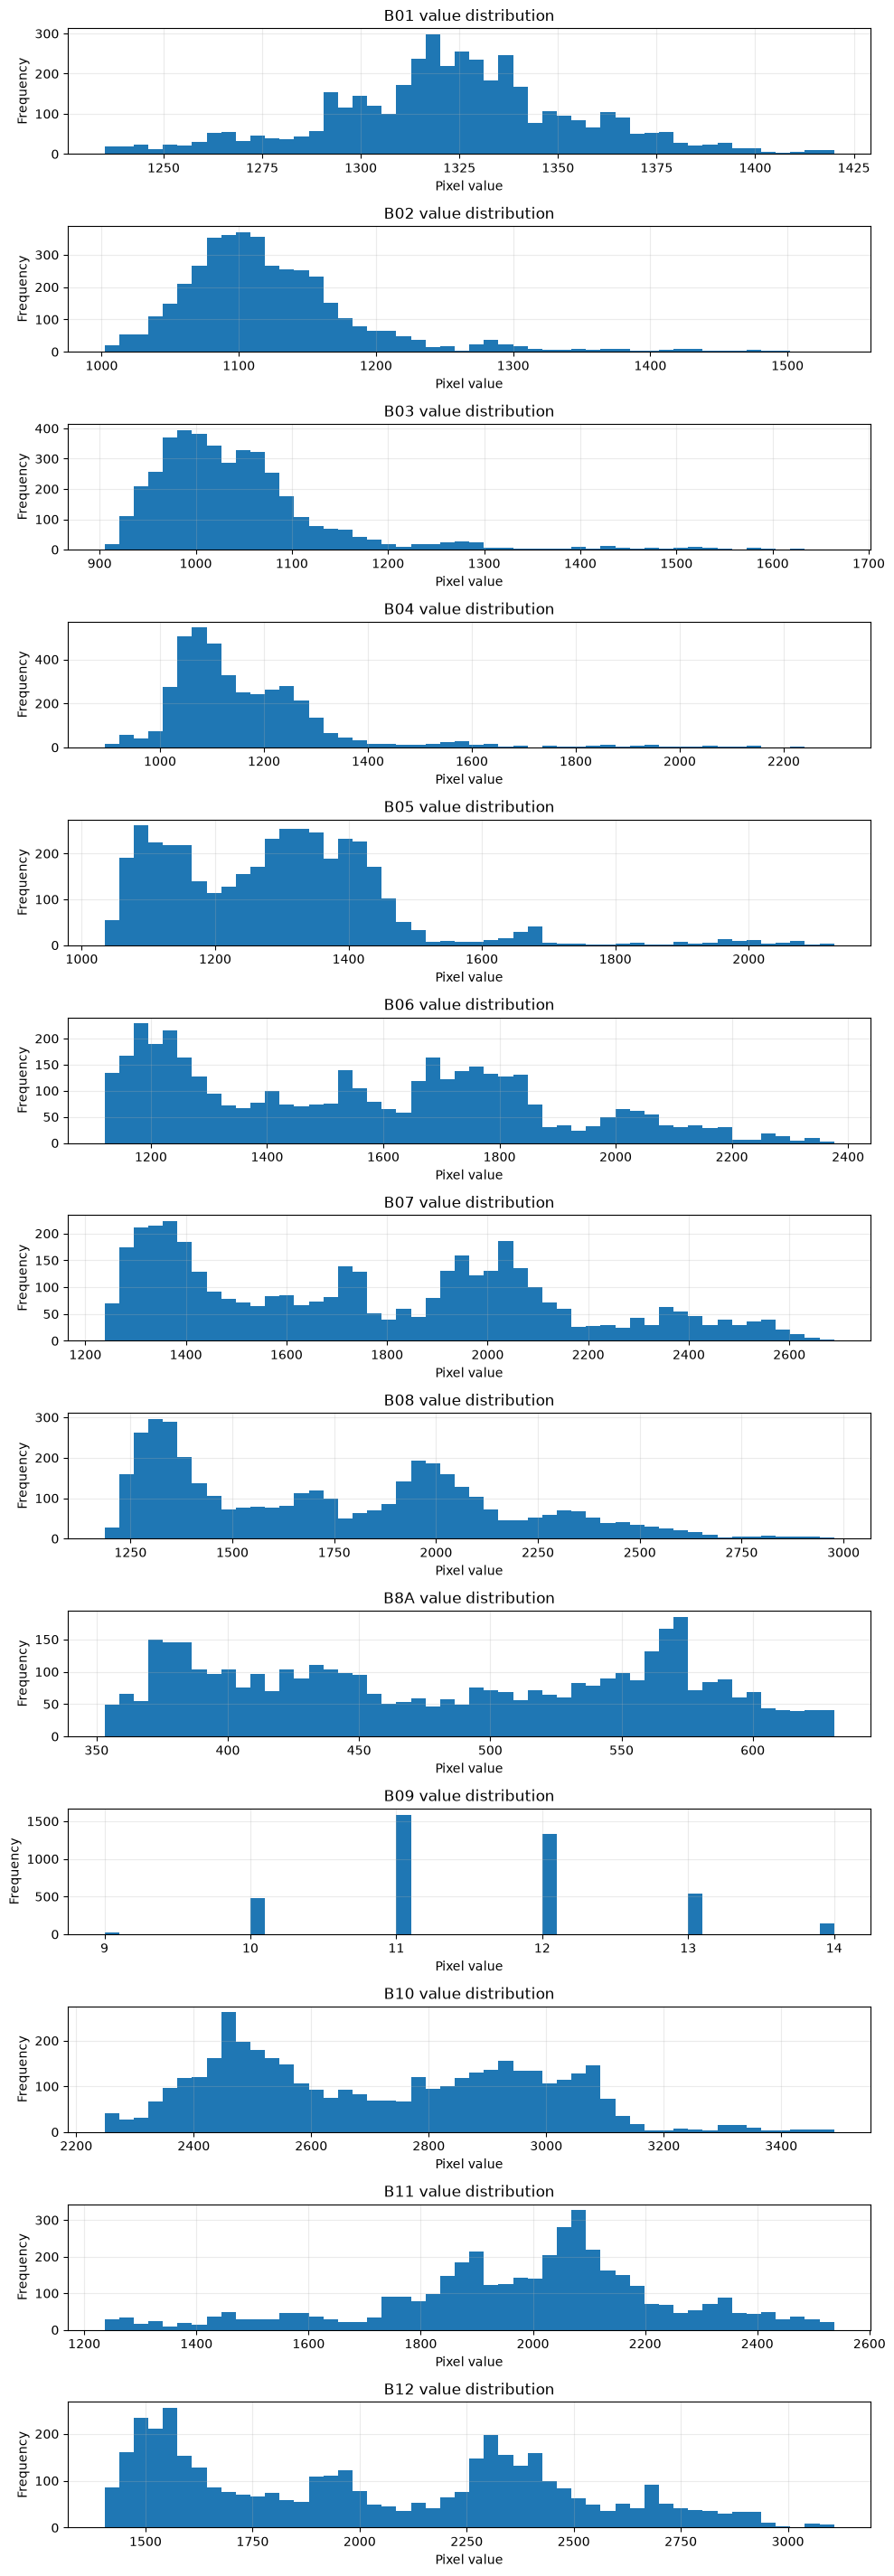

In [11]:
MAX_PIXELS_PER_BAND = 20000
rng = np.random.default_rng(SEED)

fig, axes = plt.subplots(n_show, 1, figsize=(10, max(3, 2.2 * n_show)))
if n_show == 1:
    axes = [axes]

for i, ax in enumerate(axes[:n_show]):
    values = np.asarray(sample_array[i]).ravel()
    values = values[np.isfinite(values)]
    if len(values) > MAX_PIXELS_PER_BAND:
        values = rng.choice(values, MAX_PIXELS_PER_BAND, replace=False)
    ax.hist(values, bins=50)
    band_label = STANDARD_BAND_NAMES[i] if n_bands == 13 else f"Band {i + 1}"
    ax.set_title(f"{band_label} value distribution")
    ax.set_xlabel("Pixel value")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "band_value_histograms.png", dpi=200, bbox_inches="tight")
plt.show()

## 10. Mean spectral signatures by class

For a fair runtime, this analysis samples up to a configurable number of files per class and computes mean and standard deviation per band from finite pixel values. These are dataset-derived summaries; they are not fixed or pre-filled values.

If all files have 13 bands, Sentinel-2 band names and approximate central wavelengths are used. Otherwise, generic band indices are shown.

,class,band_index,mean_pixel_value,mean_within_image_std,images_used
0,AnnualCrop,1,1432.512866,83.446852,30
1,AnnualCrop,2,1292.026213,174.990540,30
2,AnnualCrop,3,1321.795866,229.322598,30
3,AnnualCrop,4,1474.056396,449.966556,30
4,AnnualCrop,5,1737.348739,388.848444,30
5,AnnualCrop,6,2649.044189,411.445385,30
6,AnnualCrop,7,3195.149373,539.483049,30
7,AnnualCrop,8,3094.449569,548.751400,30
8,AnnualCrop,9,819.095996,92.262723,30
9,AnnualCrop,10,13.555428,1.276689,30


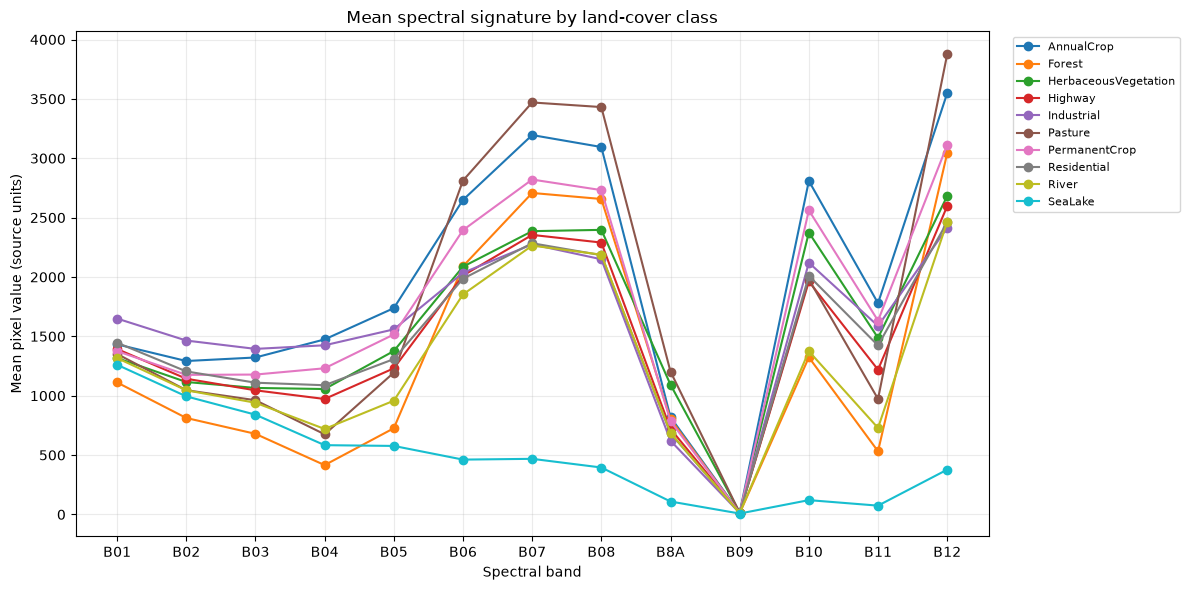

In [12]:
MAX_FILES_PER_CLASS_FOR_SIGNATURE = 30
MAX_PIXELS_PER_IMAGE = 10000

signature_records = []
signature_errors = []

for label in sorted(df["class"].unique()):
    paths = df.loc[df["class"] == label, "path"].tolist()
    if len(paths) > MAX_FILES_PER_CLASS_FOR_SIGNATURE:
        paths = random.sample(paths, MAX_FILES_PER_CLASS_FOR_SIGNATURE)

    per_image_means = []
    per_image_stds = []
    for path in paths:
        try:
            arr, _ = load_multispectral(path)
            if arr.ndim != 3:
                continue
            image_means = []
            image_stds = []
            for band in arr:
                vals = np.asarray(band).ravel()
                vals = vals[np.isfinite(vals)]
                if len(vals) == 0:
                    image_means.append(np.nan)
                    image_stds.append(np.nan)
                    continue
                if len(vals) > MAX_PIXELS_PER_IMAGE:
                    vals = rng.choice(vals, MAX_PIXELS_PER_IMAGE, replace=False)
                image_means.append(float(np.mean(vals)))
                image_stds.append(float(np.std(vals)))
            per_image_means.append(image_means)
            per_image_stds.append(image_stds)
        except Exception as exc:
            signature_errors.append({"class": label, "path": path, "error": repr(exc)})

    if per_image_means:
        mean_matrix = np.asarray(per_image_means, dtype=float)
        std_matrix = np.asarray(per_image_stds, dtype=float)
        for band_idx in range(mean_matrix.shape[1]):
            signature_records.append({
                "class": label,
                "band_index": band_idx + 1,
                "mean_pixel_value": float(np.nanmean(mean_matrix[:, band_idx])),
                "mean_within_image_std": float(np.nanmean(std_matrix[:, band_idx])),
                "images_used": int(mean_matrix.shape[0]),
            })

signatures_df = pd.DataFrame(signature_records)

if signatures_df.empty:
    print("No spectral signatures could be calculated. Check the file format and loader.")
else:
    display(signatures_df.head(15))
    signatures_df.to_csv(TABLES_DIR / "mean_spectral_signatures.csv", index=False)

    band_count_signature = int(signatures_df["band_index"].max())
    band_labels = (
        STANDARD_BAND_NAMES[:band_count_signature]
        if band_count_signature == 13
        else [f"Band {i}" for i in range(1, band_count_signature + 1)]
    )

    pivot = signatures_df.pivot(index="band_index", columns="class", values="mean_pixel_value")
    pivot.index = band_labels[:len(pivot.index)]
    plt.figure(figsize=(12, 6))
    for label in pivot.columns:
        plt.plot(pivot.index, pivot[label], marker="o", linewidth=1.5, label=label)
    plt.xlabel("Spectral band")
    plt.ylabel("Mean pixel value (source units)")
    plt.title("Mean spectral signature by land-cover class")
    plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "mean_spectral_signatures_by_class.png", dpi=200, bbox_inches="tight")
    plt.show()

if signature_errors:
    print("Signature calculation errors:", len(signature_errors))

## 11. Band correlation analysis

This analysis calculates correlations between band means from the sample image. It is a descriptive check of how band values co-vary in this image, not a model feature-importance score.

,B01,B02,B03,B04,B05,B06,B07,B08,B8A,B09,B10,B11,B12
B01,1.000,0.771,0.591,0.674,0.442,0.078,0.036,0.025,-0.102,0.474,0.621,0.838,0.000
B02,0.771,1.000,0.929,0.960,0.776,0.424,0.378,0.416,0.192,0.328,0.760,0.557,0.354
B03,0.591,0.929,1.000,0.944,0.891,0.628,0.584,0.627,0.403,0.235,0.729,0.294,0.566
B04,0.674,0.960,0.944,1.000,0.848,0.451,0.404,0.452,0.249,0.245,0.755,0.426,0.396
B05,0.442,0.776,0.891,0.848,1.000,0.797,0.765,0.771,0.666,0.046,0.835,0.026,0.770
B06,0.078,0.424,0.628,0.451,0.797,1.000,0.998,0.980,0.920,-0.103,0.665,-0.351,0.993
B07,0.036,0.378,0.584,0.404,0.765,0.998,1.000,0.981,0.930,-0.124,0.644,-0.387,0.996
B08,0.025,0.416,0.627,0.452,0.771,0.980,0.981,1.000,0.892,-0.132,0.638,-0.384,0.980
B8A,-0.102,0.192,0.403,0.249,0.666,0.920,0.930,0.892,1.000,-0.255,0.572,-0.526,0.946
B09,0.474,0.328,0.235,0.245,0.046,-0.103,-0.124,-0.132,-0.255,1.000,0.164,0.602,-0.160


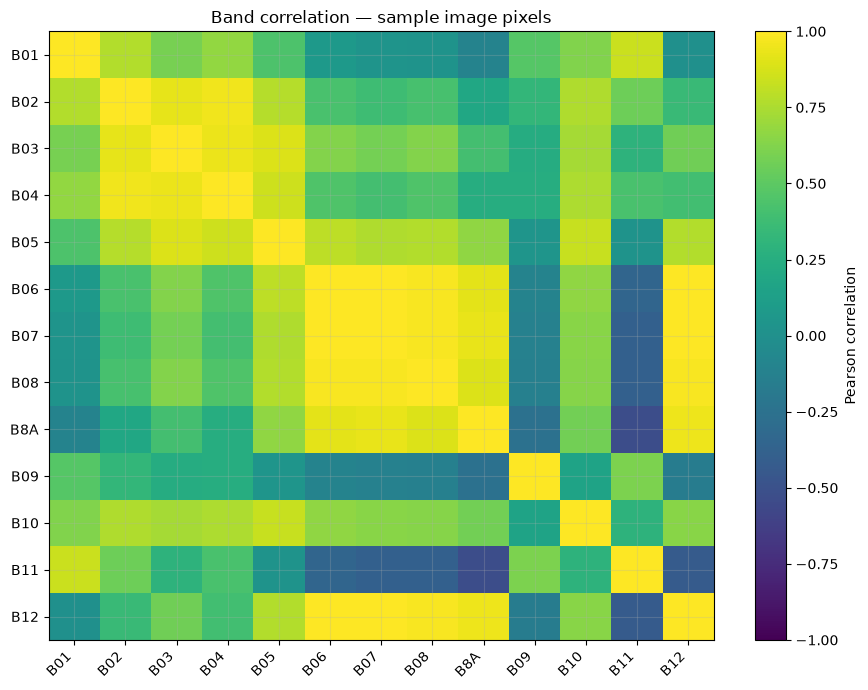

In [13]:
band_means = np.nanmean(sample_array.astype(np.float64), axis=(1, 2))
band_names_for_sample = (
    STANDARD_BAND_NAMES[:n_bands] if n_bands == 13
    else [f"Band {i + 1}" for i in range(n_bands)]
)

# Correlation across pixels, sampled for manageable runtime.
pixels_by_band = sample_array.reshape(n_bands, -1).astype(np.float64).T
if len(pixels_by_band) > 50000:
    idx = rng.choice(len(pixels_by_band), 50000, replace=False)
    pixels_by_band = pixels_by_band[idx]

pixel_df = pd.DataFrame(pixels_by_band, columns=band_names_for_sample)
corr = pixel_df.corr()
display(corr.round(3))
corr.to_csv(TABLES_DIR / "sample_band_correlation.csv")

plt.figure(figsize=(9, 7))
im = plt.imshow(corr.values, aspect="auto", vmin=-1, vmax=1)
plt.xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr.index)), corr.index)
plt.colorbar(im, label="Pearson correlation")
plt.title("Band correlation — sample image pixels")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "band_correlation_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

## 12. Optional NDVI calculation

NDVI requires red and near-infrared (NIR) reflectance bands. For the standard 13-band Sentinel-2 order used in EuroSAT MS, red is B04 (index 3) and NIR is B08 (index 7). This cell runs only when the sample has at least eight bands.

> **Caution:** NDVI interpretation is meaningful when the source bands and scaling are known. This calculation is a basic exploratory visualization and does not replace radiometric preprocessing or metadata validation.

NDVI valid-pixel mean: 0.18884718418121338
NDVI valid-pixel std: 0.09544286876916885
NDVI min/max: 0.07971656322479248 / 0.4912744462490082


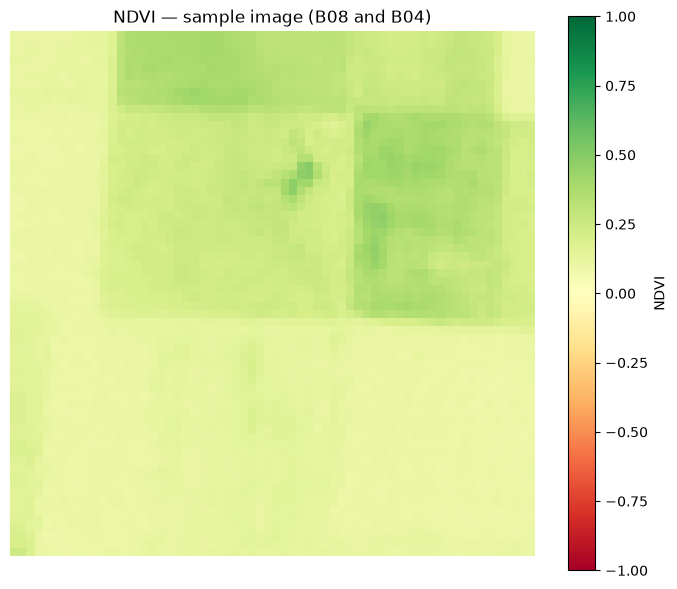

In [14]:
if sample_array.shape[0] >= 8:
    red = sample_array[3].astype(np.float32)
    nir = sample_array[7].astype(np.float32)
    denom = nir + red
    ndvi = np.divide(
        nir - red,
        denom,
        out=np.full_like(denom, np.nan, dtype=np.float32),
        where=np.abs(denom) > 1e-8,
    )
    ndvi = np.clip(ndvi, -1, 1)

    print("NDVI valid-pixel mean:", float(np.nanmean(ndvi)))
    print("NDVI valid-pixel std:", float(np.nanstd(ndvi)))
    print("NDVI min/max:", float(np.nanmin(ndvi)), "/", float(np.nanmax(ndvi)))

    plt.figure(figsize=(7, 6))
    im = plt.imshow(ndvi, vmin=-1, vmax=1, cmap="RdYlGn")
    plt.colorbar(im, label="NDVI")
    plt.title("NDVI — sample image (B08 and B04)")
    plt.axis("off")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "sample_ndvi.png", dpi=200, bbox_inches="tight")
    plt.show()
else:
    print(f"NDVI skipped: sample has {sample_array.shape[0]} band(s); red + NIR bands are required.")

## 13. Data quality checks and summary

This section produces a concise, data-driven summary of the inspected files and records any failed reads. Do not interpret the dataset as fully validated if only a sample of files was audited.

In [15]:
summary = {
    "dataset_path": str(DATA_DIR),
    "candidate_file_count": int(len(df)),
    "detected_class_count": int(df["class"].nunique()),
    "extensions": ", ".join(sorted(df["extension"].unique())),
    "sample_file": str(sample_path),
    "sample_shape_bands_height_width": str(tuple(sample_array.shape)),
    "sample_dtype": str(sample_array.dtype),
    "audit_files_attempted": int(MAX_AUDIT_FILES),
    "audit_files_read_successfully": int(len(audit_df)),
    "audit_read_errors": int(len(audit_errors)),
    "signature_errors": int(len(signature_errors)),
}

summary_df = pd.DataFrame([summary])
display(summary_df.T.rename(columns={0: "value"}))
summary_df.to_csv(TABLES_DIR / "eda_summary.csv", index=False)

print("\nSuggested interpretation checklist:")
print("- Verify that the detected sample has 13 bands if using standard EuroSAT MS.")
print("- Review the class distribution for missing or unexpectedly small classes.")
print("- Check image shapes and read errors before model training.")
print("- Use the spectral-signature plot to compare class-level band patterns.")
print("- Confirm the dataset documentation and scaling before treating pixel values as reflectance.")

,value
dataset_path,C:\Users\HP\Downloads\satellite_empty\EuroSAT_...
candidate_file_count,27000
detected_class_count,10
extensions,.tif
sample_file,C:\Users\HP\Downloads\satellite_empty\EuroSAT_...
sample_shape_bands_height_width,"(13, 64, 64)"
sample_dtype,uint16
audit_files_attempted,300
audit_files_read_successfully,300
audit_read_errors,0



Suggested interpretation checklist:
- Verify that the detected sample has 13 bands if using standard EuroSAT MS.
- Review the class distribution for missing or unexpectedly small classes.
- Check image shapes and read errors before model training.
- Use the spectral-signature plot to compare class-level band patterns.
- Confirm the dataset documentation and scaling before treating pixel values as reflectance.


## 14. Export checklist

Figures are saved to `reports/figures/` and summary tables to `reports/tables/`. The raw dataset is read-only and should generally not be committed to GitHub if it is large.

Expected output files include:
- `class_distribution.png`
- `sample_rgb_composite.png`
- `sample_images_by_class.png`
- `individual_bands.png`
- `band_value_histograms.png`
- `mean_spectral_signatures_by_class.png`
- `band_correlation_heatmap.png`
- `sample_ndvi.png` (if enough bands are present)
- CSV tables for class counts, image audit, spectral signatures, correlation, and summary